# Extended Data Fig. 8b: expression of HRD genes

Log-normalised expression of five homologous recombination genes (BRCA1, BRCA2, PALB2, RAD51C, RAD51D) on the two Visium breast cancer slides of Fig. 4.

In [1]:
import os
import warnings

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

Import required packages for minimal example.

In [2]:
import enrichmap as em
import scanpy as sc

sc.set_figure_params(frameon=False)

# repository root (the folder containing `notebooks/`); safe to re-run this cell
project_dir = os.getcwd()
if os.path.basename(project_dir) == "notebooks":
    project_dir = os.path.dirname(project_dir)
project_dir += "/"
os.chdir(project_dir)

figure_dir = project_dir + "figures/"
source_dir = project_dir + "source_data/"
os.makedirs(figure_dir, exist_ok=True)
os.makedirs(source_dir, exist_ok=True)
sc.settings.figdir = figure_dir

Read in the dataset:

In [3]:
adata = sc.read(
    project_dir + "processed_data/adata_slides_0_3.h5ad",
    backup_url="https://zenodo.org/records/15438169/files/adata_slides_0_3.h5ad?download=1",
)

100%|██████████| 563M/563M [02:29<00:00, 3.96MB/s]   


As the data is shared as raw counts, we normalise them.

In [4]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

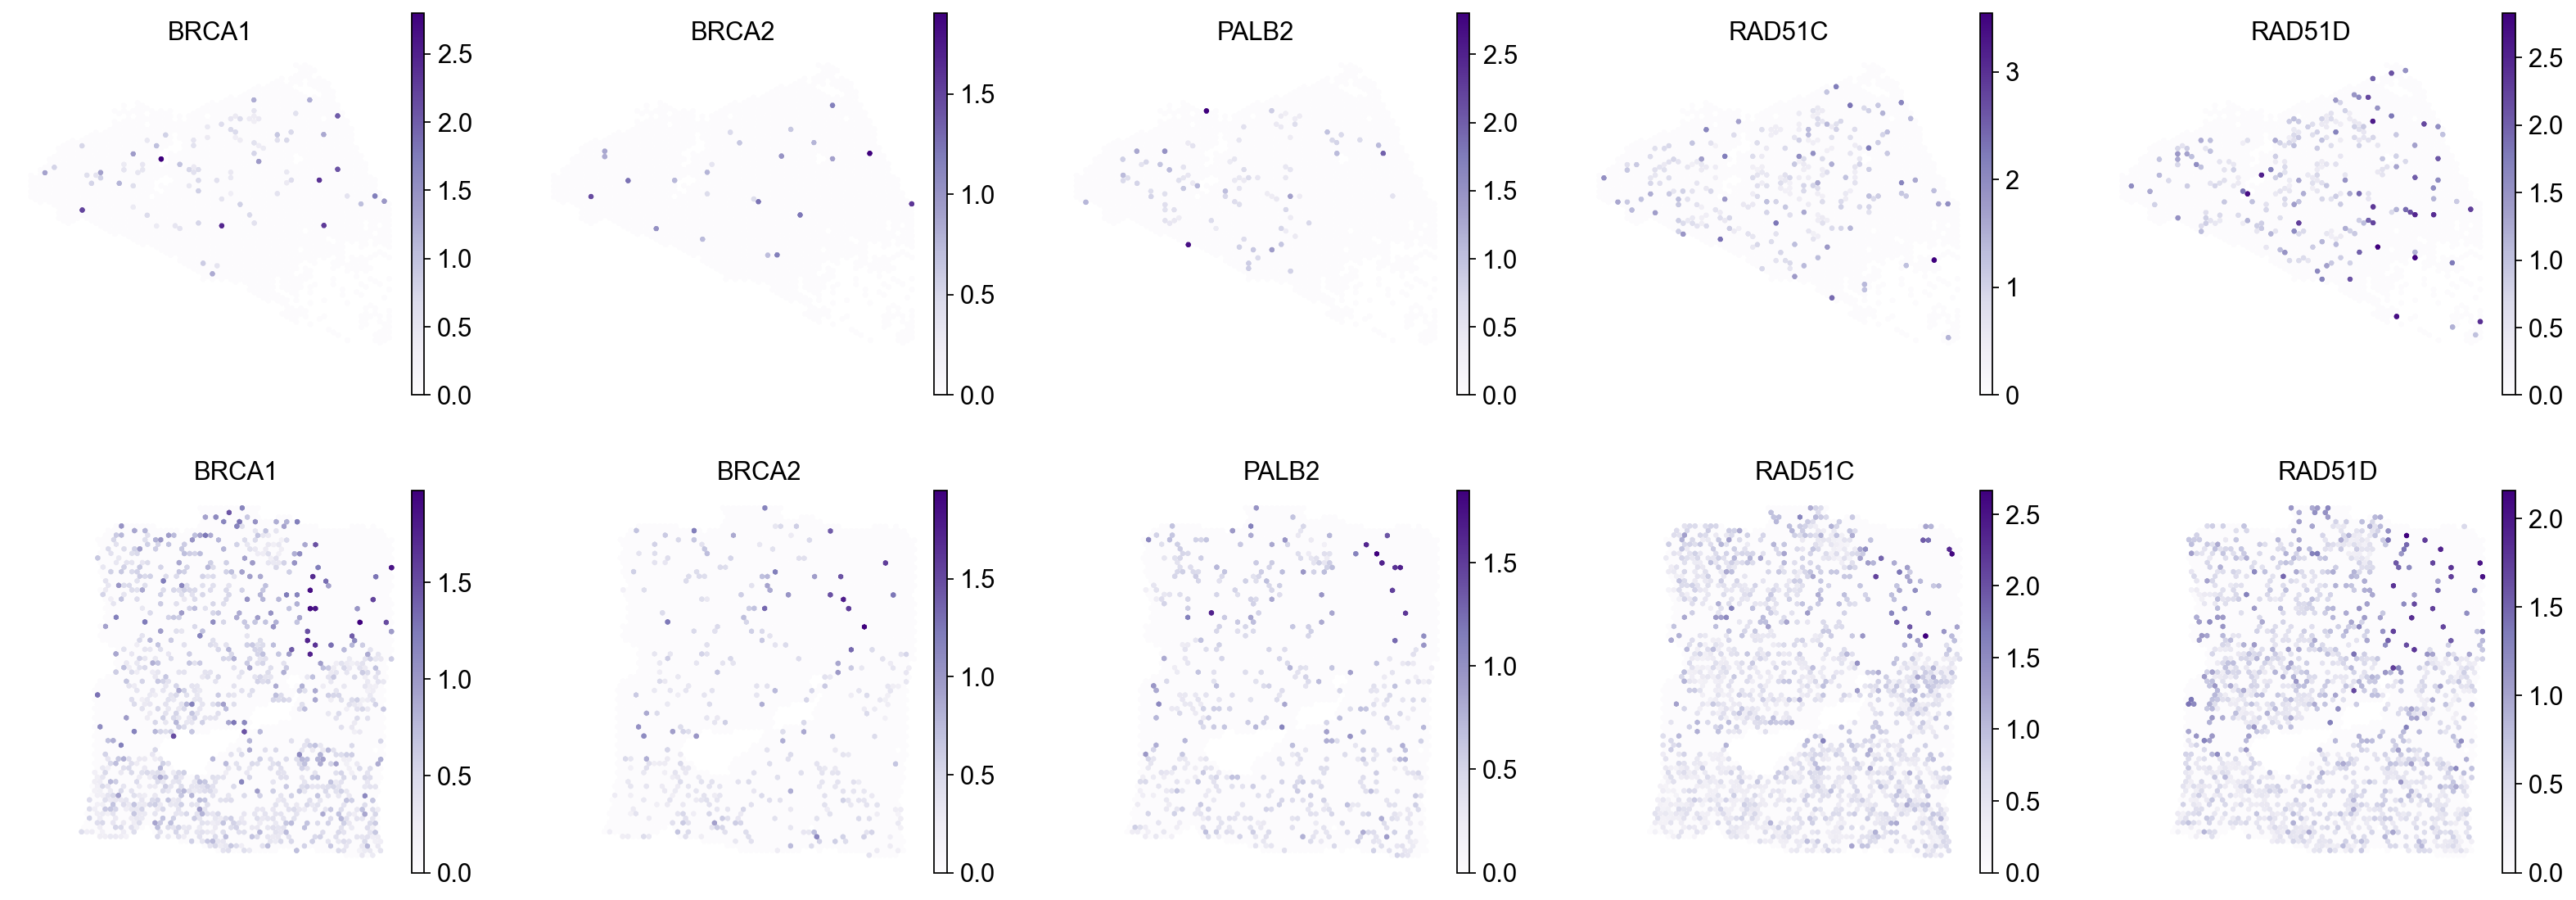

In [6]:
import squidpy as sq

sq.pl.spatial_scatter(
    adata,
    color=["BRCA1", "BRCA2", "PALB2", "RAD51C", "RAD51D"],
    size=2,
    shape=None,
    ncols=5,
    library_key="batch",
    library_id=["0", "3"],
    cmap="Purples",
    save="ExtendedDataFig8b_hrd_gene_expression.pdf",
)

In [8]:
import pandas as pd
import numpy as np
from scipy import sparse

# Genes and slides in the figure
genes = ["BRCA1", "BRCA2", "PALB2", "RAD51C", "RAD51D"]
slides = ["0", "3"]

# Subset to the plotted slides
adata_sub = adata[adata.obs["batch"].astype(str).isin(slides)].copy()

# Extract expression values
expr = adata_sub[:, genes].X
if sparse.issparse(expr):
    expr = expr.toarray()

# Extract spot-level metadata and spatial coordinates
source_data = pd.DataFrame(
    {
        "spot_id": adata_sub.obs_names.astype(str),
        "patient": adata_sub.obs["batch"].to_numpy(),
        "slide": adata_sub.obs["batch"].astype(str).to_numpy(),
        "x_pixel": adata_sub.obsm["spatial"][:, 0],
        "y_pixel": adata_sub.obsm["spatial"][:, 1],
    },
    index=adata_sub.obs_names,
)

# Add gene expression columns
source_data[genes] = np.asarray(expr)

# Save as CSV
source_data.to_csv(source_dir + "ExtendedDataFig8b_hrd_gene_expression.csv", index=False)

print(source_data.shape)
print(source_data.head())

(5870, 10)
                                                   spot_id patient slide  \
AAACAGTGTTCCTGGG-1_BRCA0-0-0  AAACAGTGTTCCTGGG-1_BRCA0-0-0       0     0   
AAACCGGGTAGGTACC-1_BRCA0-0-0  AAACCGGGTAGGTACC-1_BRCA0-0-0       0     0   
AAACCGTTCGTCCAGG-1_BRCA0-0-0  AAACCGTTCGTCCAGG-1_BRCA0-0-0       0     0   
AAACCTAAGCAGCCGG-1_BRCA0-0-0  AAACCTAAGCAGCCGG-1_BRCA0-0-0       0     0   
AAACGAAGAACATACC-1_BRCA0-0-0  AAACGAAGAACATACC-1_BRCA0-0-0       0     0   

                              x_pixel  y_pixel  BRCA1  BRCA2  PALB2    RAD51C  \
AAACAGTGTTCCTGGG-1_BRCA0-0-0     1613     1184    0.0    0.0    0.0  0.000000   
AAACCGGGTAGGTACC-1_BRCA0-0-0     1025     1349    0.0    0.0    0.0  1.775285   
AAACCGTTCGTCCAGG-1_BRCA0-0-0     1215     1196    0.0    0.0    0.0  0.000000   
AAACCTAAGCAGCCGG-1_BRCA0-0-0     1460      749    0.0    0.0    0.0  0.000000   
AAACGAAGAACATACC-1_BRCA0-0-0      342      958    0.0    0.0    0.0  0.000000   

                              RAD51D  
AAACAG